# 1 – Data Preparation: Student Dropout Prediction

**Goal:** predict whether a university student will **drop out**, stay **enrolled** or **graduate**.

**Data:** *Predict Students' Dropout and Academic Success* (UCI Machine Learning Repository) – 4,424 students, 36 features: semester results, course, tuition fees, age, family background and the economy at enrolment.

Steps: check the data → create new features → split into train and test → scale and encode → save the model-ready files.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 2. Load and check the data

In [2]:
df = pd.read_csv("data/raw/students_dropout_academic_success.csv")

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape: (4424, 37)
Missing values: 0
Duplicate rows: 0


No missing values and no duplicate rows, so nothing needs to be filled in or removed.

## 3. Target – how many students in each outcome?

target
Dropout     32.1
Enrolled    17.9
Graduate    49.9
Name: count, dtype: float64


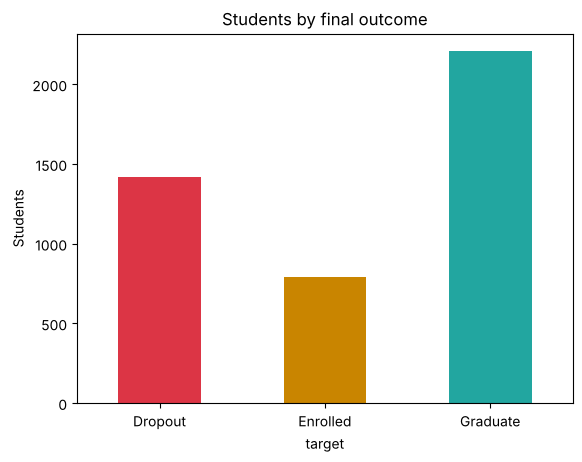

In [3]:
counts = df["target"].value_counts()[["Dropout", "Enrolled", "Graduate"]]
print((counts / len(df) * 100).round(1))

counts.plot(kind="bar", color=["#dc3545", "#c98500", "#22a6a0"], rot=0)
plt.title("Students by final outcome")
plt.ylabel("Students")
plt.show()

The classes are **imbalanced** – only 18% of students are *Enrolled* (still studying after the normal course length). Later I use **macro F1**, which gives every class the same weight, so a model cannot look good by ignoring the small class.

## 4. A quick look at the strongest signal

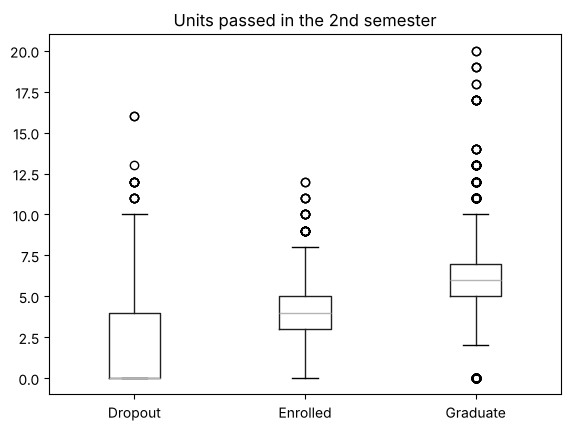

In [4]:
df.boxplot(column="Curricular units 2nd sem (approved)", by="target", grid=False)
plt.title("Units passed in the 2nd semester")
plt.suptitle("")
plt.xlabel("")
plt.show()

Students who drop out pass far fewer units. The raw counts depend on how many units a student took, so I create features that describe performance more directly.

## 5. Feature engineering – 4 new features
- `approval_rate_1st`, `approval_rate_2nd` – share of enrolled units that were passed (0 if no units were taken)
- `grade_change` – 2nd semester average grade minus 1st semester average grade (a big drop is a warning sign)
- `failed_units` – units enrolled but not passed, over both semesters

In [5]:
for s in ["1st", "2nd"]:
    enrolled = df[f"Curricular units {s} sem (enrolled)"]
    approved = df[f"Curricular units {s} sem (approved)"]
    df[f"approval_rate_{s}"] = np.where(enrolled > 0, approved / enrolled, 0)

df["grade_change"] = df["Curricular units 2nd sem (grade)"] - df["Curricular units 1st sem (grade)"]
df["failed_units"] = (df["Curricular units 1st sem (enrolled)"] - df["Curricular units 1st sem (approved)"]
                      + df["Curricular units 2nd sem (enrolled)"] - df["Curricular units 2nd sem (approved)"])

df.groupby("target")[["approval_rate_1st", "approval_rate_2nd", "grade_change", "failed_units"]].mean().round(2)

,approval_rate_1st,approval_rate_2nd,grade_change,failed_units
target,,,,
Dropout,0.38,0.29,-1.36,7.11
Enrolled,0.69,0.65,-0.01,3.53
Graduate,0.90,0.90,0.05,0.89


All four features separate the outcomes clearly: on average, dropouts passed only 29% of their 2nd-semester units, graduates 90%.

## 6. Column groups and train/test split
- **Categorical** codes (course, nationality, parents' jobs …) have no order → one-hot encoding
- **Binary** columns are already 0/1 → kept as they are
- **Numeric** columns → standard scaling

The split is **stratified** (same outcome shares in train and test) and happens **before** any scaler or encoder is fitted, so no information from the test set leaks into training.

In [6]:
categorical = ["Marital Status", "Application mode", "Course", "Previous qualification", "Nacionality",
               "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
binary = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
          "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
numeric = [c for c in df.columns if c not in categorical + binary + ["target"]]
print(len(categorical), "categorical |", len(binary), "binary |", len(numeric), "numeric columns")

X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

9 categorical | 8 binary | 23 numeric columns
Train: (3539, 40) | Test: (885, 40)


## 7. Scaling and encoding with a ColumnTransformer
- `StandardScaler` – every numeric column gets mean 0 and standard deviation 1 (needed by distance- and weight-based models such as KNN, SVM, Logistic Regression and neural networks)
- `OneHotEncoder(min_frequency=0.01)` – one 0/1 column per category; categories used by **fewer than 1%** of training students are grouped into one *infrequent* column, which keeps the number of features small
- `handle_unknown="infrequent_if_exist"` – a category never seen in training is treated as infrequent instead of causing an error

In [7]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("bin", "passthrough", binary),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False), categorical),
])

X_train_ready = preprocessor.fit_transform(X_train)     # learns means, standard deviations and categories from TRAIN only
X_test_ready = preprocessor.transform(X_test)
names = preprocessor.get_feature_names_out()

print("Features after preprocessing:", len(names))
print(names[:5], "...", names[-3:])

Features after preprocessing: 110
['num__Application order' 'num__Previous qualification (grade)'
 'num__Admission grade' 'num__Age at enrollment'
 'num__Curricular units 1st sem (credited)'] ... ["cat__Father's occupation_10" "cat__Father's occupation_90"
 "cat__Father's occupation_infrequent_sklearn"]


## 8. Save the model-ready data and the fitted preprocessor

In [8]:
train = pd.DataFrame(X_train_ready, columns=names).assign(target=y_train.values)
test = pd.DataFrame(X_test_ready, columns=names).assign(target=y_test.values)

train.to_csv("data/processed/train.csv", index=False)
test.to_csv("data/processed/test.csv", index=False)
joblib.dump(preprocessor, "models/preprocessor.joblib")

print("Saved train:", train.shape, "| test:", test.shape)

Saved train: (3539, 111) | test: (885, 111)


## Summary
- 4,424 students, no missing values or duplicates; the outcomes are imbalanced (32% Dropout, 18% Enrolled, 50% Graduate).
- 4 new features: approval rate in each semester, grade change and failed units.
- Stratified 80/20 split → 3,539 training and 885 test students.
- 23 numeric columns scaled, 8 binary columns kept, 9 categorical columns one-hot encoded with rare categories grouped → **110 features**.
- Every scaler and encoder was fitted on the training data only.
- Saved: `data/processed/train.csv`, `data/processed/test.csv` and `models/preprocessor.joblib`.